In [1]:
import sys
from pathlib import Path

import pandas as pd
from PIL import Image
from IPython.display import display

ROOT = Path.cwd()

if not (ROOT / "src").exists():
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT))

from src.qwen_client import QwenClient

PROCESSED_DIR = ROOT / "data" / "processed"

qwen = QwenClient()

print("Qwen available:", qwen.is_available())

Qwen available: True


In [2]:
observations = pd.read_parquet(
    PROCESSED_DIR / "observations.parquet"
)

images = pd.read_parquet(
    PROCESSED_DIR / "images.parquet"
)

print("Observations:", len(observations))
print("Images:", len(images))

Observations: 28132
Images: 28132


In [3]:
sample_images = images.sample(
    n=min(5, len(images))
).copy()

sample_images = sample_images.merge(
    observations[["uuid", "common_name"]],
    left_on="observation_uuid",
    right_on="uuid",
    how="left"
)

display(
    sample_images[
        ["image_id", "common_name", "image_path"]
    ]
)

,image_id,common_name,image_path
0,a5cba11c-4f25-4583-b59d-be5c151893e0,Scrub Warbler,data\raw\images\birds\a5cba11c-4f25-4583-b59d-...
1,d9b4fe3d-57b2-4461-be6f-49ca6ae9ce00,Variable Wheatear,data\raw\images\birds\d9b4fe3d-57b2-4461-be6f-...
2,87335bc8-6f68-4bdf-a7c3-ccf6b2d9a120,Rook,data\raw\images\birds\87335bc8-6f68-4bdf-a7c3-...
3,d6c115d7-855c-4a17-899f-c8dd878ecd4b,European Roller,data\raw\images\birds\d6c115d7-855c-4a17-899f-...
4,9d8d0b15-cc97-414d-bf85-dc564e008612,Spotted Flycatcher,data\raw\images\birds\9d8d0b15-cc97-414d-bf85-...


Image ID: a5cba11c-4f25-4583-b59d-be5c151893e0
Recorded species: Scrub Warbler


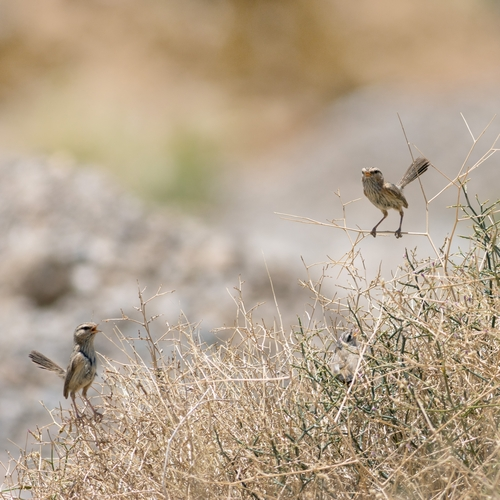

Image ID: d9b4fe3d-57b2-4461-be6f-49ca6ae9ce00
Recorded species: Variable Wheatear


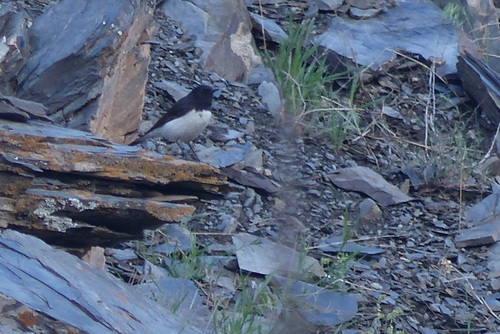

Image ID: 87335bc8-6f68-4bdf-a7c3-ccf6b2d9a120
Recorded species: Rook


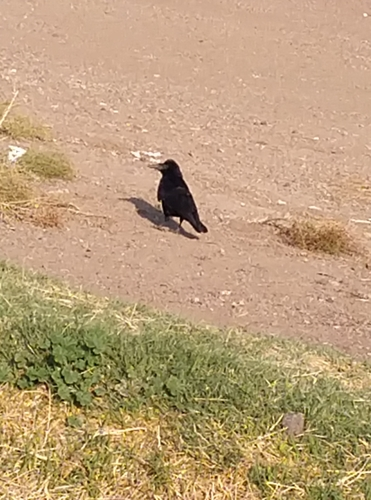

Image ID: d6c115d7-855c-4a17-899f-c8dd878ecd4b
Recorded species: European Roller


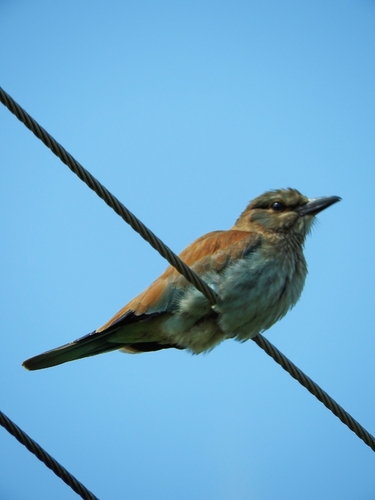

Image ID: 9d8d0b15-cc97-414d-bf85-dc564e008612
Recorded species: Spotted Flycatcher


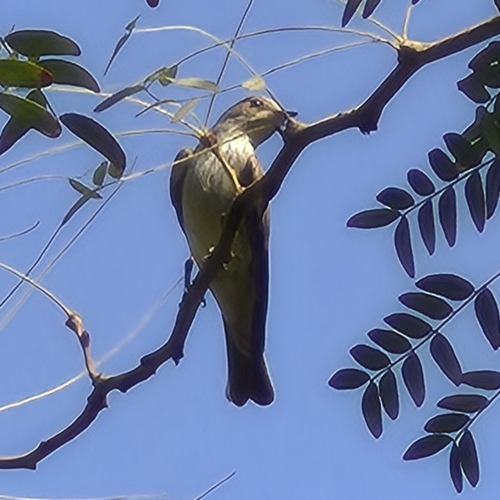

In [4]:
for _, row in sample_images.iterrows():

    image_path = ROOT / row["image_path"]

    print("Image ID:", row["image_id"])
    print("Recorded species:", row["common_name"])

    display(Image.open(image_path))

In [5]:
results = []

for _, row in sample_images.iterrows():
    image_path = ROOT / row["image_path"]

    print("Processing:", row["image_id"])

    try:
        result = qwen.assess_image(
            image_path=image_path,
            expected_species=row["common_name"]
        )

        results.append({
            "image_id": row["image_id"],
            "recorded_species": row["common_name"],
            "animal_present": result["animal_present"],
            "predicted_species": result["predicted_species"],
            "description": result["description"],
            "confidence": result["confidence"]
        })

        print(result)

    except Exception as e:
        print("Error:", e)

qwen_results = pd.DataFrame(results)
display(qwen_results)

Processing: a5cba11c-4f25-4583-b59d-be5c151893e0
{'animal_present': True, 'predicted_species': 'scrub warbler', 'description': 'A small bird with brown and white streaked plumage perched on a dry, tangled bush. Another similar bird is visible in the background.', 'confidence': 0.95}
Processing: d9b4fe3d-57b2-4461-be6f-49ca6ae9ce00
{'animal_present': True, 'predicted_species': 'Variable Wheatear', 'description': 'A small bird with a black head and white body, perched on a rock in a rocky, grassy area.', 'confidence': 0.95}
Processing: 87335bc8-6f68-4bdf-a7c3-ccf6b2d9a120
{'animal_present': True, 'predicted_species': 'black bird', 'description': 'A black bird standing on a dirt path.', 'confidence': 0.95}
Processing: d6c115d7-855c-4a17-899f-c8dd878ecd4b
{'animal_present': True, 'predicted_species': 'European Roller', 'description': 'A European Roller perched on a wire against a clear blue sky.', 'confidence': 0.95}
Processing: 9d8d0b15-cc97-414d-bf85-dc564e008612
{'animal_present': True,

,image_id,recorded_species,animal_present,predicted_species,description,confidence
0,a5cba11c-4f25-4583-b59d-be5c151893e0,Scrub Warbler,True,scrub warbler,A small bird with brown and white streaked plu...,0.95
1,d9b4fe3d-57b2-4461-be6f-49ca6ae9ce00,Variable Wheatear,True,Variable Wheatear,"A small bird with a black head and white body,...",0.95
2,87335bc8-6f68-4bdf-a7c3-ccf6b2d9a120,Rook,True,black bird,A black bird standing on a dirt path.,0.95
3,d6c115d7-855c-4a17-899f-c8dd878ecd4b,European Roller,True,European Roller,A European Roller perched on a wire against a ...,0.95
4,9d8d0b15-cc97-414d-bf85-dc564e008612,Spotted Flycatcher,True,Spotted Flycatcher,A small bird with a light-colored body and dar...,0.95


اگه بخام بیست و هشت هزار عکس و باهاش پردازش کنم لپتاپم پرواز خواهد کرد. 
